# 09 MLP on the hand-crafted features (Model 3)

The same 74 features as the logistic regression (Model 1, notebooks 05 and 08), with
hidden layers in between. LR can only draw straight boundaries between classes; the MLP
can bend them. So this tests the project's question on a model that is **more flexible
than LR, with the features held fixed**: do family labels still help?

Like the other models: binary vs family-first, with and without the TLD, trained on the
full training set and scored on the validation set.

## Settings

Training follows the CNN (notebook 03): Adam on shuffled mini-batches, the weighted
cross-entropy plus an L2 penalty, and the epoch with the highest validation macro-F1 is
kept. The MLP is small, so it uses larger batches and a larger learning rate than the CNN.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

SAMPLE = None          # None = full training set; e.g. 100_000 for a quick test
EPOCHS = 30
LR = 1e-3              # Adam learning rate
BATCH_SIZE = 1024
HIDDEN = (128, 64)     # units of the hidden layers
DROPOUT = 0.1
L2 = 1e-4              # penalty on the weights, as for LR and the CNN
SEED = 0
EVAL_SET = "val"       # "test" only for the final results
TLDS = ("yes", "no")   # with and without the TLD features
CHECKPOINTS = ROOT / "checkpoints"   # trained models are saved here (not committed)
RUN = 1                # a new number starts new trainings
OUT_DIR = ROOT / "results" / "full_val"
OUT_DIR.mkdir(parents=True, exist_ok=True)
MLFLOW_EXPERIMENT = "mlp"

## Data and features

The team's split and the 74 cached features (computed once in notebook 04). `train` is
the training set, or a sample of it if `SAMPLE` is set.

In [2]:
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from src.data.dataset import load_splits, sample_weights
from src.features.build import build_features
from src.models import tracking
from src.models.encoding import class_codes
from src.models.metrics import binary_metrics, recall_per_family
from src.models.mlp import MLP
from src.models.plots import plot_losses
from src.models.train import Split, fit, load_history, p_dga, penalty, pick_device, predict_proba, set_seed

device = pick_device()
train_full, val, test = load_splits()
feats = build_features(train_full, val, test)
name_cols, tld_cols = feats["name_cols"], feats["tld_cols"]
train = train_full.sample(n=SAMPLE, random_state=SEED) if SAMPLE else train_full
evaluate = test if EVAL_SET == "test" else val
y_val = (val["label"] == "dga").astype(int).to_numpy()
y_eval = (evaluate["label"] == "dga").astype(int).to_numpy()
classes = {"label": sorted(train_full["label"].unique()),
           "family": sorted(train_full["family"].unique())}
print(f"device: {device} | train {len(train):,} | {EVAL_SET} {len(evaluate):,} | "
      f"{len(name_cols)} name + {len(tld_cols)} TLD features")

device: cpu | train 1,599,468 | val 199,933 | 20 name + 54 TLD features


The input of the MLP: the features as a float32 matrix, one per TLD setting (all 74
features with the TLD, the 20 name features without it).

In [3]:
COLS = {"yes": name_cols + tld_cols, "no": name_cols}

def features(part, rows, tld):
    return feats[part].loc[rows.index, COLS[tld]].to_numpy(np.float32)

X = {tld: {"train": features("train", train, tld), "val": features("val", val, tld),
           "eval": features("test" if EVAL_SET == "test" else "val", evaluate, tld)}
     for tld in TLDS}
{tld: x["train"].shape for tld, x in X.items()}

{'yes': (1599468, 74), 'no': (1599468, 20)}

## 1. Define a predictor

$$p(\cdot \mid x) = \operatorname{softmax}\big(W_3\,\mathrm{ReLU}(W_2\,\mathrm{ReLU}(W_1 \tilde{x} + b_1) + b_2) + b_3\big)$$

$\tilde{x}$: the features standardized with the training mean and standard deviation
(stored in the model). Each hidden layer is a weighted sum, like LR, followed by ReLU
($\max(0, v)$), which makes the model non-linear, and dropout during training. The output
layer has 2 units (binary: `dga`, `legit`) or 104 (family-first: `legit` + 103 families);
it is the only part that differs between the setups.

In [4]:
SETUPS = {"binary": "label", "family": "family"}   # setup -> target column


def make_predictor(task, tld):
    """A new, untrained MLP with one output per class of `task`."""
    x = X[tld]["train"]
    return MLP(x.mean(0), x.std(0), {task: len(classes[task])}, HIDDEN, DROPOUT)


def predict_p_dga(model, x, task):
    """P(DGA) = 1 - P(legit), from the softmax over the classes of `task`."""
    return p_dga(predict_proba(model, x), task, classes)


model = make_predictor("family", "yes")
print(model)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

MLP(
  (body): Sequential(
    (0): Linear(in_features=74, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
  )
  (heads): ModuleDict(
    (family): Linear(in_features=64, out_features=104, bias=True)
  )
)
24,616 parameters


Before training the weights are random, so the predictor gives almost the same P(DGA) to
every domain.

In [5]:
examples = val.groupby("label").head(3)
model = make_predictor("label", "yes")
pd.DataFrame({"domain": examples["domain"].to_numpy(),
              "label": examples["label"].to_numpy(),
              "P(DGA), untrained": predict_p_dga(model, features("val", examples, "yes"), "label").round(3)})

,domain,label,"P(DGA), untrained"
0,016ff90221934b15f2b2fa291e91c212.info,dga,0.517
1,029d23144d4bd429e9639b06b7a4050d.cz.cc,dga,0.554
2,029d23144d4bd429e9639b06b7a4050d.org,dga,0.497
3,0-1.ir,legit,0.555
4,0-audiobooks.com,legit,0.552
5,000919.cn,legit,0.508


## 2. Define a loss

The loss of a batch of $B$ domains: the weighted cross-entropy, as for LR and the CNN,
plus an L2 penalty on the weights:

$$L = \frac{1}{B}\sum_{i=1}^{B} w_i\,\big(-\log p(t_i \mid x_i)\big) + \lambda \sum W^2$$

$t_i$: the training label ($y$ for binary, $z$ for family-first), $w_i$: the sample weight,
$\lambda$ = `L2`.

In [6]:
def loss_fn(model, logits, y, w, task):
    """Loss of one batch: weighted cross-entropy + L2 penalty on the weights."""
    cross_entropy = F.cross_entropy(logits[task], y, reduction="none")   # -log p(t_i | x_i)
    return (cross_entropy * w).mean() + penalty(model, 0.0, L2)

The loss of the untrained binary predictor on the first batch of the training set:

In [7]:
xb = torch.as_tensor(X["yes"]["train"][:BATCH_SIZE])
yb = torch.as_tensor(class_codes(train["label"].iloc[:BATCH_SIZE], classes["label"]))
wb = torch.as_tensor(train["weight"].iloc[:BATCH_SIZE].to_numpy(), dtype=torch.float32)
with torch.no_grad():
    loss = loss_fn(model, model(xb), yb, wb, "label")
    reg = penalty(model, 0.0, L2)
print(f"loss {loss:.4f} = weighted cross-entropy {loss - reg:.4f} + penalty {reg:.4f}")

C:\Users\amseb\AppData\Local\Temp\ipykernel_19052\1669390820.py:3: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  wb = torch.as_tensor(train["weight"].iloc[:BATCH_SIZE].to_numpy(), dtype=torch.float32)


loss 1.0771 = weighted cross-entropy 1.0706 + penalty 0.0065


## 3. Optimize the loss

Adam minimizes the loss on shuffled mini-batches, for `EPOCHS` epochs, with `fit` from
`src/models/train.py` (the same loop as the CNN). After every epoch the predictor is
scored on the validation set and the epoch with the highest macro-F1 is kept. Each
training is saved in `checkpoints/`: an interrupted training continues from its last
epoch when the cell is run again, and a finished one is only reloaded.

The MLP is not convex like LR: the result depends on the random start, hence `SEED`.

In [8]:
tracking.setup(MLFLOW_EXPERIMENT)
w_train = train["weight"].to_numpy()
w_val = sample_weights(val)


def optimize(setup, tld):
    """Train a new predictor for one setup and TLD setting."""
    task = SETUPS[setup]
    set_seed(SEED)
    model = make_predictor(task, tld)                         # step 1: the predictor
    loss = partial(loss_fn, task=task)                        # step 2: the loss
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)   # step 3: the optimizer
    history, p = fit(
        model, loss, optimizer,
        train=Split(X[tld]["train"], class_codes(train[task], classes[task]), w_train),
        val=Split(X[tld]["val"], class_codes(val[task], classes[task]), w_val, y_val),
        decide=task, classes=classes, folder=CHECKPOINTS / f"mlp_{setup}_tld-{tld}_{RUN}",
        epochs=EPOCHS, batch_size=BATCH_SIZE, seed=SEED, device=device,
        params={"model": "mlp", "setup": setup, "task": task, "tld": tld, "sample": SAMPLE,
                "lr": LR, "l2": L2, "hidden": str(HIDDEN), "dropout": DROPOUT})
    return model, history, p

Four trainings: binary and family-first, with and without the TLD. Each prints one line
per epoch and redraws its loss plot.

--- binary, TLD yes


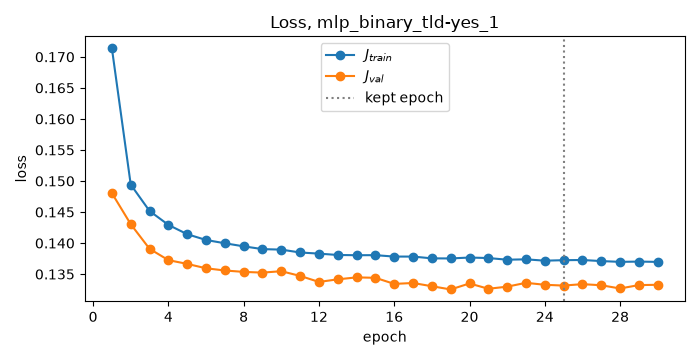

epoch  1: J_train 0.1714, J_val 0.1480 (binary 0.1414), val macro-F1 0.9474, AUC 0.9889 (19 s)
epoch  2: J_train 0.1494, J_val 0.1430 (binary 0.1359), val macro-F1 0.9501, AUC 0.9898 (17 s)
epoch  3: J_train 0.1452, J_val 0.1391 (binary 0.1314), val macro-F1 0.9524, AUC 0.9906 (18 s)
epoch  4: J_train 0.1429, J_val 0.1373 (binary 0.1292), val macro-F1 0.9532, AUC 0.9909 (17 s)
epoch  5: J_train 0.1414, J_val 0.1367 (binary 0.1282), val macro-F1 0.9525, AUC 0.9909 (17 s)
epoch  6: J_train 0.1405, J_val 0.1359 (binary 0.1273), val macro-F1 0.9540, AUC 0.9912 (17 s)
epoch  7: J_train 0.1400, J_val 0.1356 (binary 0.1267), val macro-F1 0.9538, AUC 0.9912 (16 s)
epoch  8: J_train 0.1395, J_val 0.1354 (binary 0.1264), val macro-F1 0.9542, AUC 0.9913 (18 s)
epoch  9: J_train 0.1390, J_val 0.1352 (binary 0.1261), val macro-F1 0.9553, AUC 0.9915 (17 s)
epoch 10: J_train 0.1389, J_val 0.1355 (binary 0.1261), val macro-F1 0.9540, AUC 0.9916 (18 s)
epoch 11: J_train 0.1385, J_val 0.1347 (binary 0.1

C:\Users\amseb\miniconda3\envs\ml_aub\Lib\site-packages\mlflow\models\model.py:1228: FutureWarning: `export_model` argument is deprecated. Please set `serialization_format` argument instead.
  flavor.save_model(path=local_path, mlflow_model=mlflow_model, **kwargs)


kept epoch 25 (val macro-F1 0.9567)
--- family, TLD yes


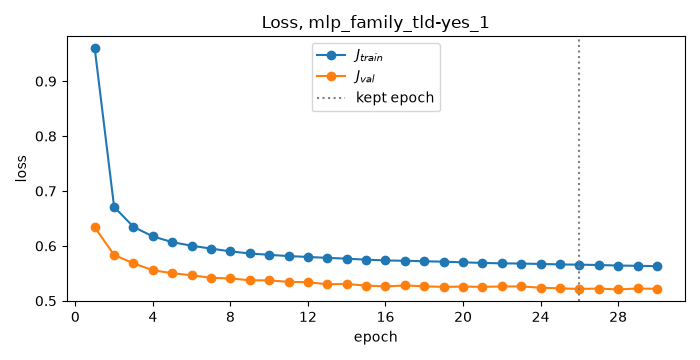

epoch  1: J_train 0.9598, J_val 0.6340 (binary 0.1402), val macro-F1 0.9498, AUC 0.9897 (17 s)
epoch  2: J_train 0.6710, J_val 0.5835 (binary 0.1327), val macro-F1 0.9523, AUC 0.9906 (17 s)
epoch  3: J_train 0.6346, J_val 0.5682 (binary 0.1306), val macro-F1 0.9525, AUC 0.9906 (17 s)
epoch  4: J_train 0.6172, J_val 0.5556 (binary 0.1278), val macro-F1 0.9539, AUC 0.9912 (16 s)
epoch  5: J_train 0.6069, J_val 0.5503 (binary 0.1267), val macro-F1 0.9537, AUC 0.9914 (16 s)
epoch  6: J_train 0.6003, J_val 0.5464 (binary 0.1265), val macro-F1 0.9538, AUC 0.9914 (16 s)
epoch  7: J_train 0.5951, J_val 0.5419 (binary 0.1251), val macro-F1 0.9538, AUC 0.9915 (16 s)
epoch  8: J_train 0.5900, J_val 0.5407 (binary 0.1252), val macro-F1 0.9543, AUC 0.9916 (16 s)
epoch  9: J_train 0.5862, J_val 0.5374 (binary 0.1242), val macro-F1 0.9551, AUC 0.9916 (16 s)
epoch 10: J_train 0.5837, J_val 0.5371 (binary 0.1258), val macro-F1 0.9538, AUC 0.9919 (17 s)
epoch 11: J_train 0.5815, J_val 0.5345 (binary 0.1

C:\Users\amseb\miniconda3\envs\ml_aub\Lib\site-packages\mlflow\models\model.py:1228: FutureWarning: `export_model` argument is deprecated. Please set `serialization_format` argument instead.
  flavor.save_model(path=local_path, mlflow_model=mlflow_model, **kwargs)


kept epoch 26 (val macro-F1 0.9567)
--- binary, TLD no


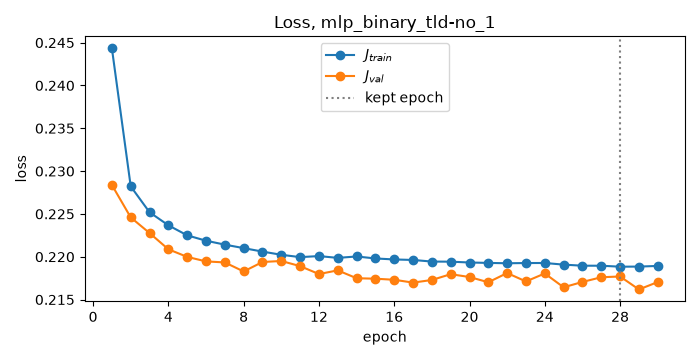

epoch  1: J_train 0.2443, J_val 0.2284 (binary 0.2221), val macro-F1 0.9246, AUC 0.9703 (15 s)
epoch  2: J_train 0.2282, J_val 0.2246 (binary 0.2187), val macro-F1 0.9256, AUC 0.9712 (14 s)
epoch  3: J_train 0.2252, J_val 0.2228 (binary 0.2168), val macro-F1 0.9264, AUC 0.9723 (15 s)
epoch  4: J_train 0.2237, J_val 0.2209 (binary 0.2147), val macro-F1 0.9261, AUC 0.9723 (15 s)
epoch  5: J_train 0.2225, J_val 0.2200 (binary 0.2136), val macro-F1 0.9271, AUC 0.9727 (15 s)
epoch  6: J_train 0.2219, J_val 0.2195 (binary 0.2129), val macro-F1 0.9274, AUC 0.9732 (16 s)
epoch  7: J_train 0.2214, J_val 0.2193 (binary 0.2126), val macro-F1 0.9277, AUC 0.9729 (16 s)
epoch  8: J_train 0.2210, J_val 0.2183 (binary 0.2114), val macro-F1 0.9283, AUC 0.9731 (15 s)
epoch  9: J_train 0.2206, J_val 0.2194 (binary 0.2123), val macro-F1 0.9279, AUC 0.9734 (16 s)
epoch 10: J_train 0.2202, J_val 0.2195 (binary 0.2123), val macro-F1 0.9271, AUC 0.9733 (15 s)
epoch 11: J_train 0.2200, J_val 0.2189 (binary 0.2

C:\Users\amseb\miniconda3\envs\ml_aub\Lib\site-packages\mlflow\models\model.py:1228: FutureWarning: `export_model` argument is deprecated. Please set `serialization_format` argument instead.
  flavor.save_model(path=local_path, mlflow_model=mlflow_model, **kwargs)


kept epoch 28 (val macro-F1 0.9295)
--- family, TLD no


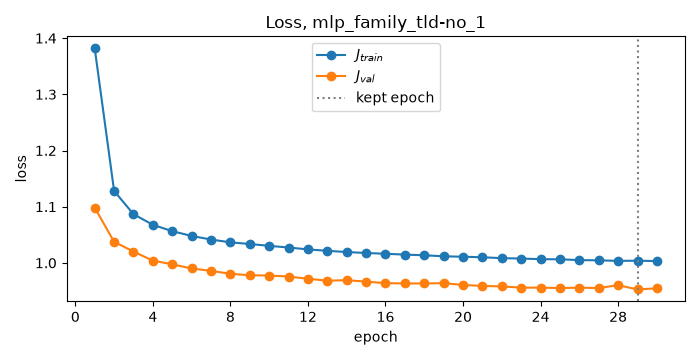

epoch  1: J_train 1.3818, J_val 1.0982 (binary 0.2209), val macro-F1 0.9251, AUC 0.9711 (15 s)
epoch  2: J_train 1.1280, J_val 1.0375 (binary 0.2163), val macro-F1 0.9258, AUC 0.9716 (14 s)
epoch  3: J_train 1.0866, J_val 1.0200 (binary 0.2161), val macro-F1 0.9259, AUC 0.9722 (15 s)
epoch  4: J_train 1.0677, J_val 1.0040 (binary 0.2127), val macro-F1 0.9275, AUC 0.9724 (16 s)
epoch  5: J_train 1.0564, J_val 0.9974 (binary 0.2118), val macro-F1 0.9285, AUC 0.9733 (17 s)
epoch  6: J_train 1.0479, J_val 0.9900 (binary 0.2111), val macro-F1 0.9288, AUC 0.9737 (18 s)
epoch  7: J_train 1.0415, J_val 0.9858 (binary 0.2100), val macro-F1 0.9286, AUC 0.9734 (19 s)
epoch  8: J_train 1.0366, J_val 0.9806 (binary 0.2100), val macro-F1 0.9293, AUC 0.9737 (19 s)
epoch  9: J_train 1.0336, J_val 0.9780 (binary 0.2093), val macro-F1 0.9295, AUC 0.9737 (20 s)
epoch 10: J_train 1.0303, J_val 0.9775 (binary 0.2103), val macro-F1 0.9287, AUC 0.9738 (21 s)
epoch 11: J_train 1.0274, J_val 0.9757 (binary 0.2

C:\Users\amseb\miniconda3\envs\ml_aub\Lib\site-packages\mlflow\models\model.py:1228: FutureWarning: `export_model` argument is deprecated. Please set `serialization_format` argument instead.
  flavor.save_model(path=local_path, mlflow_model=mlflow_model, **kwargs)


kept epoch 29 (val macro-F1 0.9313)


In [9]:
models, histories, p_val = {}, {}, {}
for tld in TLDS:
    for setup in SETUPS:
        print(f"--- {setup}, TLD {tld}")
        key = (setup, tld)
        models[key], histories[key], p_val[key] = optimize(setup, tld)

The loss of every training, and the two setups compared on the DGA/legitimate decision
(binary validation loss and validation macro-F1, on the same scale for both setups).

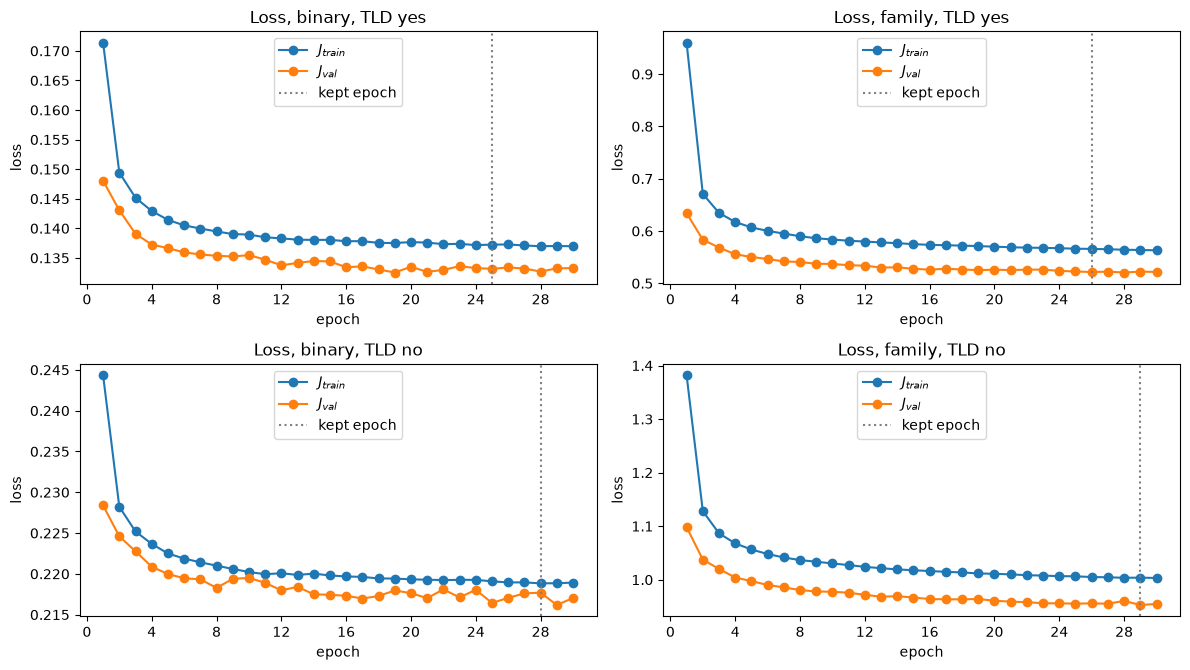

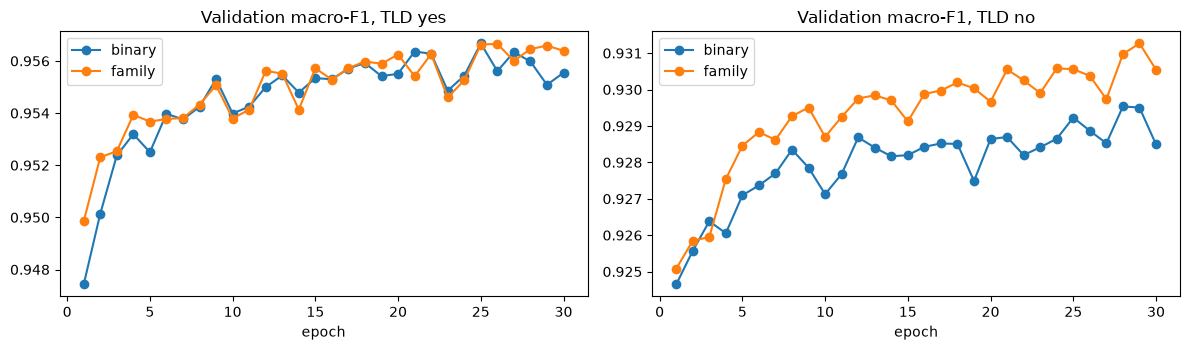

In [10]:
fig, axes = plt.subplots(len(TLDS), len(SETUPS), figsize=(12, 3.4 * len(TLDS)), squeeze=False)
for i, tld in enumerate(TLDS):
    for j, setup in enumerate(SETUPS):
        plot_losses(axes[i][j], histories[setup, tld], f"Loss, {setup}, TLD {tld}")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(TLDS), figsize=(12, 3.6), squeeze=False)
for ax, tld in zip(axes[0], TLDS):
    for setup in SETUPS:
        h = histories[setup, tld]
        ax.plot(h.index, h["macro_f1"], marker="o", label=setup)
    ax.set_title(f"Validation macro-F1, TLD {tld}")
    ax.set_xlabel("epoch")
    ax.legend()
fig.tight_layout()
plt.show()

## 4. Test the model

P(DGA) of every domain of the evaluation set; a domain is called DGA when P(DGA) ≥ 0.5,
in both setups. $\Delta$ = family-first − binary. On the validation set the
probabilities of the kept epoch were already computed in step 3. Note: the kept epoch is
chosen on the validation set, as for the CNN, so the final comparison uses the test set.

In [11]:
M = ["macro_f1", "dga_precision", "dga_recall", "roc_auc"]
p_eval = {key: p_val[key] if EVAL_SET == "val"
          else predict_p_dga(models[key], X[key[1]]["eval"], SETUPS[key[0]])
          for key in models}
rows = {}
for tld in TLDS:
    b = binary_metrics(y_eval, p_eval["binary", tld])
    f = binary_metrics(y_eval, p_eval["family", tld])
    rows[tld, "binary"] = b
    rows[tld, "family-first"] = f
    rows[tld, "Δ"] = {m: f[m] - b[m] for m in M}
table = pd.DataFrame(rows).T[M].astype(float)
table["kept epoch"] = [int(histories[("binary" if s == "binary" else "family"), t]["macro_f1"].idxmax())
                       if s != "Δ" else None for t, s in table.index]
table["kept epoch"] = table["kept epoch"].astype("Int64")
table.index.names = ["TLD", "setup"]
table.to_csv(OUT_DIR / f"mlp_full_{EVAL_SET}_results.csv")
np.savez_compressed(OUT_DIR / f"mlp_full_{EVAL_SET}_predictions.npz",
                    index=evaluate.index.to_numpy(), y_true=y_eval,
                    **{f"{s}|{t}": p.astype(np.float32) for (s, t), p in p_eval.items()})
table.round(4)

macro_f1  dga_precision  dga_recall  roc_auc  kept epoch
TLD setup                                                                 
yes binary          0.9567         0.9616      0.9513   0.9918          25
    family-first    0.9567         0.9602      0.9528   0.9921          26
    Δ              -0.0000        -0.0014      0.0014   0.0003        <NA>
no  binary          0.9295         0.9500      0.9069   0.9739          28
    family-first    0.9313         0.9499      0.9107   0.9747          29
    Δ               0.0017        -0.0001      0.0038   0.0008        <NA>

### Compared with LR

Macro-F1 and $\Delta$ of the MLP next to LR (notebook 08, same features, same split), if
LR's results file is in `results/full_val/`.

In [12]:
lr_file = OUT_DIR / "logreg_full_val_results.csv"
if lr_file.exists() and EVAL_SET == "val":
    lr = pd.read_csv(lr_file, index_col=[0, 1, 2]).loc["all features", "macro_f1"].astype(float)
    compare = pd.DataFrame({
        (model, tld): {"binary": b, "family-first": f, "Δ": f - b}
        for tld in TLDS
        for model, (b, f) in {"LR": (lr["binary", tld], lr["family", tld]),
                              "MLP": (table.loc[(tld, "binary"), "macro_f1"],
                                      table.loc[(tld, "family-first"), "macro_f1"])}.items()})
    compare.columns.names = ["model", "TLD"]
    display(compare.round(4))
else:
    print("LR results not found:", lr_file)

C:\Users\amseb\AppData\Local\Temp\ipykernel_19052\1315951560.py:3: PerformanceWarning: indexing past lexsort depth may impact performance.
  lr = pd.read_csv(lr_file, index_col=[0, 1, 2]).loc["all features", "macro_f1"].astype(float)


model,LR,MLP,LR,MLP
TLD,yes,yes,no,no
binary,0.9212,0.9567,0.9090,0.9295
family-first,0.9397,0.9567,0.9151,0.9313
Δ,0.0185,-0.0000,0.0061,0.0017


### Which DGA families are missed?

Recall of each DGA family in the two setups (with the TLD), and the 10 families with the
lowest recall in the family-first setup.

In [13]:
tld = TLDS[0]
recall = pd.DataFrame({
    setup: recall_per_family(evaluate["family"], y_eval, (p_eval[setup, tld] >= 0.5).astype(int))
    for setup in SETUPS})
recall.columns = ["binary", "family-first"]
recall.sort_values("family-first").head(10).round(3)

,binary,family-first
matsnu,0.059,0.059
nymaim2,0.102,0.188
bigviktor,0.516,0.484
bigviktor_subdomain,0.575,0.525
qsnatch,0.603,0.576
gozi,0.709,0.677
suppobox,0.661,0.727
nivdort,0.690,0.756
vawtrak,0.781,0.763
darkshell,0.800,0.789


**Result.** *(filled in after the run: the gains $\Delta$ with and without the TLD, and how
they compare with LR's +0.0185 and +0.0061 and the CNN's +0.0004.)*